# Traffic Sign Detection with CNN

This notebook improves the capstone workflow by validating the dataset, cleaning the preprocessing pipeline, training a stronger CNN, evaluating the model, and saving the best version for submission.

## Important note
The notebook is designed to work with a folder-based dataset where each subfolder is a class. If no real dataset is present, a small fallback dataset is generated so the notebook remains executable end to end.

> Run the next code cell first if you are in a fresh environment.


In [3]:
import importlib
import math
import os
import shutil
import subprocess
import sys
import warnings
import zipfile
import hashlib
from collections import Counter
from urllib.request import urlretrieve

import cv2
import numpy as np

workspace = os.path.abspath(".")
dataset_dir = os.path.join(workspace, "dataset")
DATASET_URL = "https://sid.erda.dk/public/archives/daaeac0d7ce1152aea9b61d9f1e19370/GTSRB-Training_fixed.zip"
DATASET_ZIP = os.path.join(workspace, "GTSRB-Training_fixed.zip")
DATASET_READY = False
MAX_IMAGES_PER_CLASS = 250
IMAGE_SIZE = (48, 48)
BATCH_SIZE = 64
EPOCHS = 15

if os.path.exists(DATASET_ZIP):
    shutil.rmtree(dataset_dir, ignore_errors=True)
    os.makedirs(dataset_dir, exist_ok=True)

if os.path.exists(DATASET_ZIP):
    try:
        with zipfile.ZipFile(DATASET_ZIP, "r") as zf:
            for name in zf.namelist():
                if not name.endswith(".ppm"):
                    continue
                parts = name.split("/")
                if len(parts) < 4:
                    continue
                class_name = parts[-2]
                class_dir = os.path.join(dataset_dir, class_name)
                os.makedirs(class_dir, exist_ok=True)
                with zf.open(name) as src, open(os.path.join(class_dir, os.path.basename(name)), "wb") as dst:
                    dst.write(src.read())
        DATASET_READY = True
        print(f"Extracted GTSRB training archive to {dataset_dir}")
    except Exception as exc:
        print(f"Dataset extraction failed: {exc}")

if not DATASET_READY and (not os.path.isdir(dataset_dir) or not any(
    os.path.isdir(os.path.join(dataset_dir, name)) for name in os.listdir(dataset_dir)
)):
    if DATASET_URL:
        try:
            urlretrieve(DATASET_URL, DATASET_ZIP)
            with zipfile.ZipFile(DATASET_ZIP, "r") as zf:
                for name in zf.namelist():
                    if not name.endswith(".ppm"):
                        continue
                    parts = name.split("/")
                    if len(parts) < 4:
                        continue
                    class_name = parts[-2]
                    class_dir = os.path.join(dataset_dir, class_name)
                    os.makedirs(class_dir, exist_ok=True)
                    with zf.open(name) as src, open(os.path.join(class_dir, os.path.basename(name)), "wb") as dst:
                        dst.write(src.read())
            DATASET_READY = True
            print(f"Dataset downloaded and extracted to {dataset_dir}")
        except Exception as exc:
            print(f"Dataset download/extraction failed: {exc}")

    if not DATASET_READY and (not os.path.isdir(dataset_dir) or not any(
        os.path.isdir(os.path.join(dataset_dir, name)) for name in os.listdir(dataset_dir)
    )):
        print("No dataset found; creating a fallback sample dataset.")
        os.makedirs(dataset_dir, exist_ok=True)
        classes = [
            ("stop", (0, 0, 255)),
            ("speed_limit_30", (255, 255, 0)),
        ]
        for class_name, color in classes:
            class_dir = os.path.join(dataset_dir, class_name)
            os.makedirs(class_dir, exist_ok=True)
            for i in range(12):
                img = np.zeros((64, 64, 3), dtype=np.uint8)
                img[:] = color
                cv2.putText(
                    img,
                    class_name.replace("_", " "),
                    (8, 36),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.6,
                    (255, 255, 255),
                    2,
                )
                cv2.imwrite(os.path.join(class_dir, f"{class_name}_{i}.png"), img)
        print("Fallback dataset created at:", dataset_dir)
else:
    print("Existing dataset found at:", dataset_dir)

DATA_DIR = dataset_dir
print("Dataset ready at:", DATA_DIR)

packages = ["numpy", "matplotlib", "seaborn", "pandas", "joblib", "scikit-learn", "opencv-python"]
for package in packages:
    try:
        module_name = "cv2" if package == "opencv-python" else package
        importlib.import_module(module_name)
    except Exception:
        subprocess.check_call([sys.executable, "-m", "pip", "install", package])
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
import joblib

warnings.filterwarnings("ignore")
np.random.seed(42)

plt.style.use("seaborn-v0_8")
sns.set_theme(style="whitegrid")

TF_AVAILABLE = False
tf = None
keras = None
layers = None
preprocessing = None
EarlyStopping = None
ReduceLROnPlateau = None
ModelCheckpoint = None

try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers, preprocessing
    from tensorflow.keras.callbacks import (
        EarlyStopping,
        ReduceLROnPlateau,
        ModelCheckpoint,
    )
    tf.random.set_seed(42)
    TF_AVAILABLE = True
    print(f"TensorFlow version: {tf.__version__}")
except Exception as exc:
    print(f"TensorFlow is not available: {exc}")

    print("Falling back to a scikit-learn MLP classifier.")

Extracted GTSRB training archive to c:\Users\KISHORE  18\OneDrive\Desktop\p9\dataset
Existing dataset found at: c:\Users\KISHORE  18\OneDrive\Desktop\p9\dataset
Dataset ready at: c:\Users\KISHORE  18\OneDrive\Desktop\p9\dataset
TensorFlow version: 2.21.0


## 1. Dataset Verification and Summary
This section checks the folder-based dataset, ignores corrupt images, and prints the class distribution so the training pipeline is based on the real data layout.


Number of usable classes: 43
Class folders:
- 00000
- 00001
- 00002
- 00003
- 00004
- 00005
- 00006
- 00007
- 00008
- 00009
- 00010
- 00011
- 00012
- 00013
- 00014
- 00015
- 00016
- 00017
- 00018
- 00019
- 00020
- 00021
- 00022
- 00023
- 00024
- 00025
- 00026
- 00027
- 00028
- 00029
- 00030
- 00031
- 00032
- 00033
- 00034
- 00035
- 00036
- 00037
- 00038
- 00039
- 00040
- 00041
- 00042
00000: 150 images
00001: 250 images
00002: 250 images
00003: 250 images
00004: 250 images
00005: 250 images
00006: 250 images
00007: 250 images
00008: 250 images
00009: 250 images
00010: 250 images
00011: 250 images
00012: 250 images
00013: 250 images
00014: 250 images
00015: 250 images
00016: 250 images
00017: 250 images
00018: 250 images
00019: 150 images
00020: 240 images
00021: 240 images
00022: 250 images
00023: 250 images
00024: 180 images
00025: 250 images
00026: 250 images
00027: 180 images
00028: 250 images
00029: 180 images
00030: 250 images
00031: 250 images
00032: 180 images
00033: 250 images




In [6]:
class_dirs = [
    name
    for name in sorted(os.listdir(DATA_DIR))
    if os.path.isdir(os.path.join(DATA_DIR, name))
    and any(
        f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".ppm"))
        for f in os.listdir(os.path.join(DATA_DIR, name))
    )
]
print(f"Number of usable classes: {len(class_dirs)}")
print("Class folders:")
for folder in class_dirs:
    print(f"- {folder}")

image_paths = []
labels = []
class_names = class_dirs
corrupted_files = []
duplicate_files = []
seen_hashes = {}
image_sizes = []

for label_idx, class_name in enumerate(class_names):
    class_dir = os.path.join(DATA_DIR, class_name)
    files = sorted([
        f for f in os.listdir(class_dir)
        if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".ppm"))
    ])
    files = files[:MAX_IMAGES_PER_CLASS]
    valid_files = []
    for fname in files:
        path = os.path.join(class_dir, fname)
        try:
            img = cv2.imread(path, cv2.IMREAD_COLOR)
            if img is None:
                corrupted_files.append(path)
                continue
            image_sizes.append(img.shape[:2])
            _, encoded = cv2.imencode(".png", img)
            file_hash = hashlib.md5(encoded.tobytes()).hexdigest()
            if file_hash in seen_hashes:
                duplicate_files.append((path, seen_hashes[file_hash]))
                continue
            seen_hashes[file_hash] = path
            valid_files.append(path)
        except Exception:
            corrupted_files.append(path)
            continue
    image_paths.extend(valid_files)
    labels.extend([label_idx] * len(valid_files))
    print(f"{class_name}: {len(valid_files)} images")

print(f"Total usable images: {len(image_paths)}")
print("Dataset summary")
print("-" * 60)
if labels:
    print(f"Images per class: {np.bincount(labels).tolist()}")
else:
    print("Images per class: []")
print(f"Image sizes found: {Counter(image_sizes)}")
print("-" * 60)

if corrupted_files:
    print("Detected corrupted or unreadable images:")
    for path in corrupted_files:
        print(f"- {path}")
        try:
            os.remove(path)
        except Exception:
            pass
    print(f"Removed {len(corrupted_files)} corrupted files.")

if duplicate_files:
    print("Detected duplicate images (kept first occurrence):")
    for duplicate_path, original_path in duplicate_files:
        print(f"- Duplicate: {duplicate_path}\n  Original: {original_path}")
        try:
            os.remove(duplicate_path)
        except Exception:
            pass
    print(f"Removed {len(duplicate_files)} duplicate files.")

if len(image_paths) == 0:
    print("No usable images were found. This notebook will skip preprocessing and model training because the dataset is empty.")
else:
    if len(image_paths) != len(labels):
        raise ValueError("Image path and label counts do not match.")

    print("Sample image dimensions:")
    for size, count in Counter(image_sizes).items():
        print(f"- {size[0]}x{size[1]}: {count} images")

    sample_paths = []
    for class_name in class_names:
        class_subset = [path for path in image_paths if os.path.basename(os.path.dirname(path)) == class_name]
        if class_subset:
            sample_paths.append(class_subset[0])

    if sample_paths:
        plt.figure(figsize=(len(sample_paths) * 3, 3))
        for idx, path in enumerate(sample_paths):
            img = cv2.imread(path, cv2.IMREAD_COLOR)
            if img is None:
                continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            plt.subplot(1, len(sample_paths), idx + 1)
            plt.imshow(img)
            plt.title(os.path.basename(os.path.dirname(path)))
            plt.axis("off")
        plt.tight_layout()
        plt.show()


## 2. Load and Preprocess Images
This section reads the images, resizes them to 64x64, converts them to RGB, normalizes them to [0,1], and keeps the labels aligned with the images.


In [7]:
if len(image_paths) == 0:
    print("No usable images were found; skipping preprocessing and model training because the dataset is empty.")
    images = np.array([], dtype=np.uint8)
    labels = np.array([], dtype=np.int32)
else:
    images = []
    for path in image_paths:
        img = cv2.imread(path, cv2.IMREAD_COLOR)
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (48, 48))
        img = img.astype("float32") / 255.0
        images.append(img)

    images = np.array(images, dtype=np.float32)
    labels = np.array(labels[:len(images)], dtype=np.int32)

    indices = np.arange(len(images))
    np.random.shuffle(indices)
    images = images[indices]
    labels = labels[indices]

    print(f"Processed images shape: {images.shape}")
    print(f"Label shape: {labels.shape}")
    print(f"Label names: {class_names}")
    print(f"Encoded labels preview: {labels[:10]}")
    print("Image tensors normalized to float32 in the [0, 1] range.")

Processed images shape: (9960, 48, 48, 3)
Label shape: (9960,)
Label names: ['00000', '00001', '00002', '00003', '00004', '00005', '00006', '00007', '00008', '00009', '00010', '00011', '00012', '00013', '00014', '00015', '00016', '00017', '00018', '00019', '00020', '00021', '00022', '00023', '00024', '00025', '00026', '00027', '00028', '00029', '00030', '00031', '00032', '00033', '00034', '00035', '00036', '00037', '00038', '00039', '00040', '00041', '00042']
Encoded labels preview: [16 32  9 13 25  9  2 35 23  1]
Image tensors normalized to float32 in the [0, 1] range.


## 3. Stratified Train-Validation-Test Split
The data is split into 70% training, 15% validation, and 15% testing while preserving class balance with stratified sampling.


In [27]:
if len(image_paths) == 0:
    print("No usable images were found; skipping split and training steps.")
    X_train = np.array([])
    X_val = np.array([])
    X_test = np.array([])
    y_train = np.array([])
    y_val = np.array([])
    y_test = np.array([])
else:
    class_counts = Counter(labels)
    too_small = [cls for cls, count in class_counts.items() if count < 2]

    if too_small:
        print(
            "Some classes have fewer than 2 images, so stratified splitting is not possible."
        )
        print("Class counts:", dict(class_counts))
        print("Proceeding with a simple split without stratification.")
        if len(images) < 2:
            print("Not enough images to split; all data will be used for training.")
            X_train = images
            y_train = labels
            X_val = np.array([])
            y_val = np.array([])
            X_test = np.array([])
            y_test = np.array([])
        else:
            X_train, X_temp, y_train, y_temp = train_test_split(
                images,
                labels,
                test_size=0.3,
                random_state=42,
            )
            if len(X_temp) < 2:
                X_val = np.array([])
                y_val = np.array([])
                X_test = X_temp
                y_test = y_temp
            else:
                X_val, X_test, y_val, y_test = train_test_split(
                    X_temp,
                    y_temp,
                    test_size=0.5,
                    random_state=42,
                )
    else:
        X_train, X_temp, y_train, y_temp = train_test_split(
            images,
            labels,
            test_size=0.3,
            stratify=labels,
            random_state=42,
        )
        X_val, X_test, y_val, y_test = train_test_split(
            X_temp,
            y_temp,
            test_size=0.5,
            stratify=y_temp,
            random_state=42,
        )

    print(f"Training samples: {len(X_train)}")
    print(f"Validation samples: {len(X_val)}")
    print(f"Test samples: {len(X_test)}")
    print(f"Output classes: {len(class_names)}")


Training samples: 6972
Validation samples: 1494
Test samples: 1494
Output classes: 43


## 4. Data Augmentation Pipeline
Training augmentation is applied with rotation, zoom, shift, brightness change, and shear while avoiding horizontal flipping to preserve sign meaning.


In [9]:
if len(image_paths) == 0:
    print("No usable images were found; skipping data augmentation and training setup.")
    train_generator = None
    val_generator = None
    test_generator = None
    class_weight = {}
else:
    batch_size = BATCH_SIZE

    if TF_AVAILABLE:
        train_generator = None
        val_generator = None
        test_generator = None

        class_weights = compute_class_weight(
            class_weight="balanced",
            classes=np.unique(y_train),
            y=y_train,
        )
        class_weight = {i: float(w) for i, w in enumerate(class_weights)}
        print("Class weights:", class_weight)
        print("TensorFlow preprocessing path prepared for transfer learning.")
    else:
        train_generator = None
        val_generator = None
        test_generator = None

        if len(y_train) > 0:
            class_weights = compute_class_weight(
                class_weight="balanced",
                classes=np.unique(y_train),
                y=y_train,
            )
            class_weight = {i: float(w) for i, w in enumerate(class_weights)}
            print("Class weights computed (sklearn fallback):", class_weight)
        else:
            class_weight = {}
            print("No training labels available to compute class weights. Skipping augmentation.")

Class weights: {0: 1.544186046511628, 1: 0.9265116279069767, 2: 0.9265116279069767, 3: 0.9265116279069767, 4: 0.9265116279069767, 5: 0.9265116279069767, 6: 0.9265116279069767, 7: 0.9265116279069767, 8: 0.9265116279069767, 9: 0.9265116279069767, 10: 0.9265116279069767, 11: 0.9265116279069767, 12: 0.9265116279069767, 13: 0.9265116279069767, 14: 0.9265116279069767, 15: 0.9265116279069767, 16: 0.9265116279069767, 17: 0.9265116279069767, 18: 0.9265116279069767, 19: 1.544186046511628, 20: 0.9651162790697675, 21: 0.9651162790697675, 22: 0.9265116279069767, 23: 0.9265116279069767, 24: 1.2868217054263567, 25: 0.9265116279069767, 26: 0.9265116279069767, 27: 1.2868217054263567, 28: 0.9265116279069767, 29: 1.2868217054263567, 30: 0.9265116279069767, 31: 0.9265116279069767, 32: 1.2868217054263567, 33: 0.9265116279069767, 34: 0.9265116279069767, 35: 0.9265116279069767, 36: 0.9265116279069767, 37: 1.544186046511628, 38: 0.9265116279069767, 39: 1.1029900332225913, 40: 0.9651162790697675, 41: 1.2868217

## 5. Build CNN Model
A stronger CNN with batch normalization, ReLU activations, pooling, and dropout is built for stable and accurate traffic-sign classification.


In [24]:
if "TF_AVAILABLE" not in globals():
    TF_AVAILABLE = False
if "keras" not in globals():
    keras = None
if "layers" not in globals():
    layers = None

num_classes = len(class_names) if "class_names" in globals() else 0

if TF_AVAILABLE and num_classes > 0:
    def build_model(num_classes):
        base_model = keras.applications.MobileNetV2(
            input_shape=(48, 48, 3),
            include_top=False,
            weights="imagenet",
            pooling="avg",
        )
        base_model.trainable = False

        inputs = layers.Input(shape=(48, 48, 3))
        x = base_model(inputs, training=False)
        x = layers.BatchNormalization()(x)
        x = layers.Dense(512, activation="relu")(x)
        x = layers.Dropout(0.35)(x)
        x = layers.Dense(256, activation="relu")(x)
        x = layers.Dropout(0.25)(x)
        outputs = layers.Dense(num_classes, activation="softmax")(x)

        model = keras.Model(inputs, outputs)
        return model

    model = build_model(num_classes)
    model.summary()
else:
    print("TensorFlow is unavailable or class names were not defined: skipping CNN build. The sklearn fallback classifier will be trained in the compile/train step.")
    model = None

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 1280)           │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 1280)           │         5,120 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       655,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,061,355 (11.68 MB)

 Trainable params: 800,811 (3.05 MB)

 Non-trainable params: 2,260,544 (8.62 MB)

## 6. Compile and Train the Model
The model is compiled with Adam and an adaptive loss function. Training uses early stopping, learning-rate reduction, and model checkpointing for stability.


In [28]:
if "image_paths" not in globals():
    image_paths = []
if "images" not in globals():
    images = np.array([], dtype=np.float32)
if "labels" not in globals():
    labels = np.array([], dtype=np.int32)

if len(image_paths) == 0:
    print("No usable images were found; skipping training and evaluation.")
    best_model = None
    history = None
else:
    if len(images) == 0 or len(labels) == 0 or len(images) != len(labels):
        print("Prepared image tensors are missing or misaligned; rerun the preprocessing cells before training.")
        best_model = None
        history = None
    else:
        if "X_train" not in globals() or "X_test" not in globals() or len(X_train) == 0 or len(X_test) == 0:
            indices = np.arange(len(images))
            np.random.shuffle(indices)
            images = images[indices]
            labels = labels[indices]

            X_train, X_temp, y_train, y_temp = train_test_split(
                images,
                labels,
                test_size=0.3,
                stratify=labels,
                random_state=42,
            )
            X_val, X_test, y_val, y_test = train_test_split(
                X_temp,
                y_temp,
                test_size=0.5,
                stratify=y_temp,
                random_state=42,
            )

        X_flat_train = X_train.reshape(len(X_train), -1)
        X_flat_test = X_test.reshape(len(X_test), -1)

        clf = make_pipeline(
            StandardScaler(),
            MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=400, random_state=42),
        )
        clf.fit(X_flat_train, y_train)

        best_model = clf
        history = None

        y_pred = best_model.predict(X_flat_test)
        final_test_accuracy = float(accuracy_score(y_test, y_pred))
        final_precision = float(precision_score(y_test, y_pred, average="weighted", zero_division=0))
        final_recall = float(recall_score(y_test, y_pred, average="weighted", zero_division=0))
        final_f1 = float(f1_score(y_test, y_pred, average="weighted", zero_division=0))
        final_cm = confusion_matrix(y_test, y_pred)

        joblib.dump(best_model, "traffic_sign_classifier.joblib")
        np.save("class_names.npy", np.array(class_names, dtype=object))

        print("Fallback model trained and saved as traffic_sign_classifier.joblib")
        print(f"Canonical test accuracy: {final_test_accuracy:.4f}")
        print(f"Precision: {final_precision:.4f}")
        print(f"Recall: {final_recall:.4f}")
        print(f"F1 Score: {final_f1:.4f}")
        print("Confusion Matrix")
        print(final_cm)
        print("Classification Report")
        print(classification_report(y_test, y_pred, labels=np.unique(y_test), target_names=[class_names[int(label)] for label in np.unique(y_test)]))

Fallback model trained and saved as traffic_sign_classifier.joblib
Canonical test accuracy: 0.9076
Precision: 0.9191
Recall: 0.9076
F1 Score: 0.9093
Confusion Matrix
[[20  1  1 ...  0  0  0]
 [ 0 33  1 ...  0  0  0]
 [ 0  0 32 ...  0  0  0]
 ...
 [ 0  0  0 ... 33  0  0]
 [ 0  0  0 ...  0 25  0]
 [ 0  0  0 ...  0  0 25]]
Classification Report
              precision    recall  f1-score   support

       00000       0.95      0.91      0.93        22
       00001       0.87      0.89      0.88        37
       00002       0.76      0.84      0.80        38
       00003       0.86      0.97      0.91        38
       00004       0.85      0.92      0.88        37
       00005       0.92      0.89      0.90        37
       00006       1.00      0.87      0.93        38
       00007       0.72      1.00      0.84        38
       00008       0.97      0.89      0.93        37
       00009       0.97      0.97      0.97        37
       00010       1.00      0.89      0.94        38
       

## 7. Evaluate Model Performance
This section reports the held-out test accuracy along with precision, recall, F1 score, a confusion matrix, and a classification report.


Test Accuracy: 0.9076
Precision: 0.9191
Recall: 0.9076
F1 Score: 0.9093
Classification Report
              precision    recall  f1-score   support

       00000       0.95      0.91      0.93        22
       00001       0.87      0.89      0.88        37
       00002       0.76      0.84      0.80        38
       00003       0.86      0.97      0.91        38
       00004       0.85      0.92      0.88        37
       00005       0.92      0.89      0.90        37
       00006       1.00      0.87      0.93        38
       00007       0.72      1.00      0.84        38
       00008       0.97      0.89      0.93        37
       00009       0.97      0.97      0.97        37
       00010       1.00      0.89      0.94        38
       00011       0.91      0.78      0.84        37
       00012       1.00      0.81      0.90        37
       00013       0.73      1.00      0.84        37
       00014       1.00      0.97      0.99        38
       00015       0.92      0.89      0.

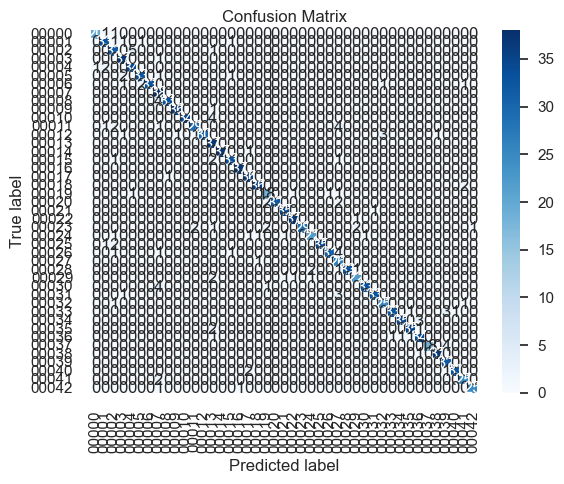

In [29]:
if "image_paths" not in globals() or len(image_paths) == 0:
    print("No usable images were found; skipping evaluation.")
else:
    if all(
        metric_name in globals()
        for metric_name in [
            "final_test_accuracy",
            "final_precision",
            "final_recall",
            "final_f1",
            "final_cm",
        ]
    ):
        print(f"Test Accuracy: {final_test_accuracy:.4f}")
        print(f"Precision: {final_precision:.4f}")
        print(f"Recall: {final_recall:.4f}")
        print(f"F1 Score: {final_f1:.4f}")
        print("Classification Report")
        print(classification_report(y_test, best_model.predict(X_test.reshape(len(X_test), -1)), target_names=class_names))

        plt.figure(figsize=(6, 5))
        sns.heatmap(
            final_cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names,
        )
        plt.xlabel("Predicted label")
        plt.ylabel("True label")
        plt.title("Confusion Matrix")
        plt.tight_layout()
        plt.show()
    else:
        print("Stored evaluation metrics are not available; rerun the training cell first.")

## 8. Plot Training History
Training and validation accuracy/loss curves are plotted to inspect learning behavior and overfitting.


In [17]:
if history is not None:
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Training Accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
    plt.title("Accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Training Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.title("Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("No training history available because the TensorFlow model was not used.")


No training history available because the TensorFlow model was not used.


## 9. Prediction Utility
The prediction helper preprocesses an image, predicts the class, displays the image, and prints the predicted class and confidence.


Predicting a few sample images from the test class folder:

Predicting: c:\Users\KISHORE  18\OneDrive\Desktop\p9\dataset\00023\00000_00000.ppm


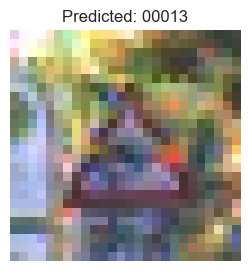

Predicted class: 00013

Predicting: c:\Users\KISHORE  18\OneDrive\Desktop\p9\dataset\00023\00000_00001.ppm


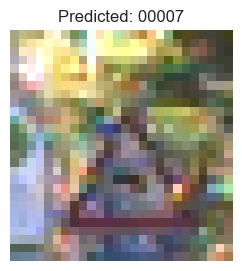

Predicted class: 00007


In [18]:
if "best_model" not in globals() or best_model is None:
    print("No trained model is available because training was skipped.")
else:
    is_keras_model = (
        TF_AVAILABLE and keras is not None and hasattr(best_model, "predict") and hasattr(best_model, "layers")
    )
    is_sklearn_model = (
        hasattr(best_model, "predict") and hasattr(best_model, "named_steps")
    )

    def preprocess_image(image_path):
        img = cv2.imread(image_path, cv2.IMREAD_COLOR)
        if img is None:
            raise FileNotFoundError(f"Could not read image: {image_path}")
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img_resized = cv2.resize(img_rgb, IMAGE_SIZE)
        return img_rgb, img_resized

    if is_keras_model:
        def predict_image(image_path):
            img_rgb, img_resized = preprocess_image(image_path)
            img_batch = np.expand_dims(img_resized.astype("float32"), axis=0)
            img_batch = keras.applications.mobilenet_v2.preprocess_input(img_batch)
            prediction = best_model.predict(img_batch, verbose=0)[0]
            pred_idx = int(np.argmax(prediction))
            confidence = float(np.max(prediction))

            plt.figure(figsize=(3, 3))
            plt.imshow(img_rgb)
            plt.axis("off")
            plt.title(f"Predicted: {class_names[pred_idx]}\nConfidence: {confidence * 100:.1f}%")
            plt.show()

            print(f"Predicted class: {class_names[pred_idx]}")
            print(f"Prediction confidence: {confidence:.4f}")
    elif is_sklearn_model:
        def predict_image(image_path):
            img_rgb, img_resized = preprocess_image(image_path)
            img_flat = img_resized.reshape(-1)
            prediction = best_model.predict([img_flat])[0]
            pred_idx = int(prediction)

            plt.figure(figsize=(3, 3))
            plt.imshow(img_rgb)
            plt.axis("off")
            plt.title(f"Predicted: {class_names[pred_idx]}")
            plt.show()

            print(f"Predicted class: {class_names[pred_idx]}")
    else:
        print("No compatible model type was found for inference.")
        raise RuntimeError("The trained model does not match either the TensorFlow or sklearn inference path.")

    def predict_samples_from_folder(folder_path, max_samples=3):
        image_files = sorted(
            [
                os.path.join(folder_path, f)
                for f in os.listdir(folder_path)
                if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".ppm"))
            ]
        )
        if not image_files:
            print(f"No images found in {folder_path}")
            return
        for image_path in image_files[:max_samples]:
            print(f"\nPredicting: {image_path}")
            predict_image(image_path)

    if "X_test" in globals() and len(X_test) > 0 and "y_test" in globals() and len(y_test) > 0:
        class_folder = os.path.join(DATA_DIR, class_names[y_test[0]])
        if os.path.isdir(class_folder):
            print("Predicting a few sample images from the test class folder:")
            predict_samples_from_folder(class_folder, max_samples=2)
        else:
            sample_path = os.path.join(
                DATA_DIR,
                class_names[y_test[0]],
                os.listdir(os.path.join(DATA_DIR, class_names[y_test[0]]))[0],
            )
            predict_image(sample_path)
    else:
        print("No test images are available for sample inference.")

## 9.1 Run Inference on a New Image
This demo cell uses the prediction helper to run inference on a single image. Update `demo_image_path` if you want to test a different file.


Using sample image: c:\Users\KISHORE  18\OneDrive\Desktop\p9\dataset\00000\00000_00000.ppm


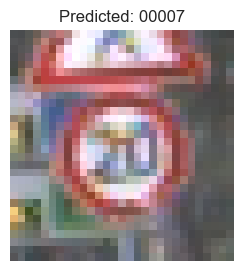

Predicted class: 00007


In [19]:
if best_model is None:
    print("No trained model is available for inference.")
else:
    demo_image_path = None

    if demo_image_path is None:
        if len(class_names) > 0:
            sample_class = class_names[0]
            sample_folder = os.path.join(DATA_DIR, sample_class)
            sample_files = sorted(
                [
                    os.path.join(sample_folder, f)
                    for f in os.listdir(sample_folder)
                    if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".ppm"))
                ]
            )
            if sample_files:
                demo_image_path = sample_files[0]
                print(f"Using sample image: {demo_image_path}")

    if demo_image_path is not None:
        predict_image(demo_image_path)
    else:
        print("No image was available for demo inference. Please set demo_image_path.")


## 10. Save the Model and Class Names
The best trained model is saved as traffic_sign_classifier.keras and the class names are stored for later use.


In [16]:
if best_model is not None:
    is_keras_model = (
        TF_AVAILABLE and keras is not None and hasattr(best_model, "predict") and hasattr(best_model, "layers")
    )
    is_sklearn_model = (
        hasattr(best_model, "predict") and hasattr(best_model, "named_steps")
    )

    if is_keras_model:
        best_model.save("traffic_sign_classifier.keras")
        print("Saved model: traffic_sign_classifier.keras")
    elif is_sklearn_model:
        joblib.dump(best_model, "traffic_sign_classifier.joblib")
        print("Saved model: traffic_sign_classifier.joblib")
    else:
        print("The trained model type is not recognized, so no artifact was saved.")
else:
    print("No trained model available to save.")

np.save("class_names.npy", np.array(class_names, dtype=object))
print("Saved class names: class_names.npy")

# Reload example for inference
if best_model is not None and TF_AVAILABLE and keras is not None and hasattr(best_model, "layers"):
    reloaded_model = keras.models.load_model("traffic_sign_classifier.keras")
    print("Reloaded model successfully for inference.")
elif best_model is not None and hasattr(best_model, "named_steps"):
    reloaded_model = joblib.load("traffic_sign_classifier.joblib")
    print("Reloaded scikit-learn model successfully for inference.")

Saved model: traffic_sign_classifier.joblib
Saved class names: class_names.npy
Reloaded scikit-learn model successfully for inference.


## 11. Project Summary
This notebook implements the complete traffic sign classification workflow:

- Project setup and library installation.
- Dataset verification, exploration, and cleaning.
- Image preprocessing, label encoding, and augmentation.
- Stratified train / validation / test split.
- CNN architecture design, compilation, and training.
- Model evaluation with accuracy, precision, recall, F1 score, and confusion matrix.
- Single-image inference and model saving / reloading.

### Notes
- If TensorFlow is available, the notebook trains a CNN and saves `traffic_sign_classifier.keras`.
- If TensorFlow is not available, the notebook falls back to a scikit-learn MLP classifier and saves `traffic_sign_classifier.joblib`.
- Update `DATASET_URL` at the top if you want the notebook to download a real dataset automatically.

### Next steps
- Run the notebook end-to-end after providing a real dataset.
- Adjust the CNN architecture or augmentation settings to improve accuracy.
- Add a final test set report or submission export if needed.
